# allamaraine

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
! pip install ultralytics
! pip install easyocr

In [ ]:
import cv2
import numpy as np
from IPython.display import display
from PIL import Image
import os
import easyocr
from matplotlib import pyplot as plt
from ultralytics import YOLO

In [ ]:
srcVideoList = []
src_vdo_folder = "/content/drive/MyDrive/chessProgram/chess_vdo"
des_vdo_folder = "/content/drive/MyDrive/chessProgram/chess_out_vdo"
des_log_folder = "/content/drive/MyDrive/chessProgram/chess_out_vdo"
des_pgn_path   = "/content/drive/MyDrive/chessProgram/chess_pgn"
DEBUG_EN          = True
DEBUG_CONSOLE_EN  = True
DEBUG_LOG_FILE_EN = True
debugFrameBGR     = None
frameNumber       = 0

outLog            = None
outVideo          = None



```
## This is formatted as code
```

## Visualizer, Debugger, and IO

In [ ]:
def embededLine(image_bgr, lines, color_bgr):
    for rho, theta in lines:
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 3000 * (-b))
        y1 = int(y0 + 3000 * (a))
        x2 = int(x0 - 3000 * (-b))
        y2 = int(y0 - 3000 * (a))
        cv2.line(image_bgr, (x1, y1), (x2, y2), color_bgr, 2)


def embededPoint(image_bgr, point, radius = 40):

    color = (0,0,255)
    thickness = -1
    cv2.circle(image_bgr, point[::-1], radius, color, thickness)

def embededParameter(image_bgr, values: list):     # embed also support  gray scale image

    text = f"\n".join(values)
    position = (60, 30)  # Adjust position for each line
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1
    color = (0, 255, 0)  # Green text
    thickness = 2

    cv2.putText(image_bgr, text, position, font, font_scale, color, thickness)

def initAll_debugger(srcVideoCapture, srcVideoNameWoType):
    global outVideo, outLog

    txtlg_path = os.path.join(des_log_folder, srcVideoNameWoType + ".txt")
    vdolg_path = os.path.join(des_vdo_folder, srcVideoNameWoType + ".mp4")

    if DEBUG_LOG_FILE_EN:
        outLog = open(txtlg_path, 'w')
    if DEBUG_EN:
        fps      = int(srcVideoCapture.get(cv2.CAP_PROP_FPS))
        width    = int(srcVideoCapture.get(cv2.CAP_PROP_FRAME_WIDTH))
        height   = int(srcVideoCapture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fourcc   = cv2.VideoWriter_fourcc(*'mp4v')
        outVideo = cv2.VideoWriter(vdolg_path, fourcc, fps, (width, height))

def log(s:str):
    if DEBUG_LOG_FILE_EN:
        outLog.write(f"[FRAME] {str(frameNumber)} : {s}\n")

def doneLog():
    if DEBUG_LOG_FILE_EN:
        outLog.close()

def doneVideoLog():
    if DEBUG_EN:
        outVideo.release()

def doneAll_debugger():
  doneLog()
  doneVideoLog()

In [ ]:
def collectNameWoType(folderPath):
  fileList = [f for f in os.listdir(folderPath)
              if os.path.isfile(os.path.join(folderPath, f))]

  fileListWoType = [os.path.splitext(f)[0] for f in fileList]

  return fileListWoType

def initVideoReader(fileNameWithoutType):

  src_vdo_path = os.path.join(src_vdo_folder, fileNameWithoutType + ".mp4")

  return cv2.VideoCapture(src_vdo_path)




## Board State System

In [ ]:
CHESS_ROW_SZ = 8
CHESS_COL_SZ = 8
AMT_CHESS_PIECE = 6

# piece index and maximum amount of the piece chess per side
PID_PAWN   = 0; MAX_AMT_PAWN   = 8
PID_ROOK   = 1; MAX_AMT_ROOK   = 2
PID_KNIGHT = 2; MAX_AMT_KNIGHT = 2
PID_BISHOP = 3; MAX_AMT_BISHOP = 2
PID_KING   = 4; MAX_AMT_KING   = 1
PID_QUEEN  = 5; MAX_AMT_QUEEN  = 1
PID_EMPTY  = 6; MAX_AMT_EMPTY  = 64

pidStrMap = ["PID_PAWN","ROOK"
            ,"KNIGHT","BISHOP"
            ,"KING","QUEEN"
            ,"EMPTY"]

PID_CFLEVEL_THRESHOLD = int(50)
simMap = {
(PID_PAWN,   PID_PAWN  ) : int(100),
(PID_ROOK,   PID_ROOK  ) : int(100),
(PID_KNIGHT, PID_KNIGHT) : int(100),
(PID_BISHOP, PID_BISHOP) : int(100),
(PID_KING,   PID_KING  ) : int(100),
(PID_QUEEN,  PID_QUEEN ) : int(100),
(PID_QUEEN,  PID_KING  ) : int(75 ),
(PID_KING,   PID_QUEEN ) : int(75 ),
}

CID_WHITE = 0
CID_BLACK = 1

# the changing tuple idx
class CH:
    def __init__(self, x,y, pid, vote):
        self.x    = x
        self.y    = y
        self.pid  = pid
        self.vote = vote

    def __str__(self):
      return f"[srcxy: ({self.x},{self.y}) pid: {pidStrMap[self.pid]} voteVal: {self.vote}]"

    def __repr__(self):
      return self.__str__()


M_TYPE_NO_MOVE = 0
M_TYPE_MOVE    = 1
M_TYPE_DIED    = 2

class MV:
    def __init__(self,
                 moveType = M_TYPE_NO_MOVE, \
                 src_x    = CHESS_ROW_SZ, src_y = CHESS_COL_SZ, \
                 des_x    = CHESS_ROW_SZ, des_y = CHESS_COL_SZ,
                 pid      = PID_EMPTY,
                 cfLevel  = int(0)):
        self.moveType = moveType
        self.src_x    = src_x
        self.src_y    = src_y
        self.des_x    = des_x
        self.des_y    = des_y
        self.pid      = pid
        self.cfLevel  = cfLevel

    def __str__(self):

      moveMap = ["M_TYPE_NO_MOVE", "M_TYPE_MOVE", "M_TYPE_DIED"]
      ret = f"[mt: {moveMap[self.moveType]} "
      ret = ret + f"srcxy: ({self.src_x},{self.src_y}) "
      ret = ret + f"desxy: ({self.des_x},{self.des_y}) "
      ret = ret + f"pid: {pidStrMap[self.pid]} "
      ret = ret + f"cfl: {str(self.cfLevel)}]"

      return ret

    def __repr__(self):
      return self.__str__()

def checkPidCflevel(pidSrc, pidDes):
    if (pidSrc, pidDes) in simMap:
      return simMap[(pidSrc, pidDes)]
    else:
      return 0

def cvt_cid_pid_to_str(cid, pid):
    ans = "white_" if cid == CID_WHITE else "black_"
    ans = ans + pidStrMap[pid]
    return ans

def cvt_vote_state_board_to_str(state):
    rs = str()
    for r in range(CHESS_ROW_SZ):
        for c in range(CHESS_COL_SZ):
            rs = rs + pidStrMap[state[r][c]] + " "
        rs = rs + "\n"
    return rs


CAPTURE_POS = (CHESS_ROW_SZ, CHESS_COL_SZ)
MAXIMUM_WINDOW_SZ = 1024

In [ ]:
class BoardData:
    # it contains current status of  the board
    # first two first dimension is board slot and the value is the piece chess type

    def __init__(self, param_confidentValue):
        self.confidentValue = param_confidentValue
        # current state
        self.curStates = np.zeros((2, CHESS_ROW_SZ, CHESS_COL_SZ), dtype=np.int8)
        ##### first for white and second for black
        self.nextFrames = 0
        self.curSize    = 0
        self.frames = np.zeros((2, MAXIMUM_WINDOW_SZ, CHESS_ROW_SZ, CHESS_COL_SZ, AMT_CHESS_PIECE + 1), dtype=np.int64)

    def getCurState(self, cid):
      return self.curStates[cid]

    def addFrame(self, whiteFrame, blackFrame):

        self.frames[CID_WHITE][self.nextFrames] = whiteFrame
        self.frames[CID_BLACK][self.nextFrames] = blackFrame
        self.nextFrames = (self.nextFrames + 1) % MAXIMUM_WINDOW_SZ
        self.curSize    = min(self.curSize + 1, MAXIMUM_WINDOW_SZ)


    def vote(self, cid):

        frames_cid = self.frames[cid]

        voteBoard = np.zeros((CHESS_ROW_SZ, CHESS_COL_SZ, AMT_CHESS_PIECE + 1), dtype=np.int64)

        if (self.curSize > self.nextFrames):
            voteBoard = np.sum(frames_cid[:self.nextFrames], axis=0)
            remain    = self.curSize - self.nextFrames
            voteBoard = voteBoard + np.sum(frames_cid[-remain:], axis=0)
        else:
            voteBoard = np.sum(frames_cid[(self.nextFrames - self.curSize):self.nextFrames], axis=0)

        #print("vb", voteBoard)

        pieceResultIdx = np.argmax(voteBoard, axis=2)
        pieceResultVal = np.max   (voteBoard, axis=2)

        return pieceResultIdx, pieceResultVal

    def resetFrames(self):
        self.nextFrames = 0
        self.curSize    = 0


    def detectMove(self, cid, newState, newStateVoteVal): # return [missing from board] [appear]

        missingList = [] # (x,y, pid, voteValue)
        appearList  = [] # (x,y, pid, voteValue)

        oldState = self.curStates[cid]

        for r in range(CHESS_ROW_SZ):
            for c in range(CHESS_COL_SZ):
                #### detect missing
                if ((oldState[r][c] != PID_EMPTY) and (newState[r][c] == PID_EMPTY)):
                   missingList.append(CH(r,c, oldState[r][c], newStateVoteVal[r][c]))
                #### detect appear
                if ((oldState[r][c] == PID_EMPTY) and (newState[r][c] != PID_EMPTY)):
                   appearList.append(CH(r,c, newState[r][c], newStateVoteVal[r][c]))

        return missingList, appearList


    def updateState(self, cid, newState):
        self.curStates[cid] = newState


    #retur (moveType, src_x,src_y, des_x, des_y, pid)
    def analyzeMove(self, ml: list, al: list, cs):
        # sort with confident value
        sorted_ml = sorted(ml, key= lambda x : x.vote, reverse=True)
        # sort with confident value


        missing = None if (len(sorted_ml) == 0) else sorted_ml[0]
        #appear  = None if (len(sorted_al) == 0) else sorted_al[0]

        if missing == None:
            return MV()


        ###### for now we so sure that we are not have
        sorted_al = sorted(al, key= lambda x : \
                           checkPidCflevel(cs[missing.x][missing.y], x.pid), reverse=True)
        for ap in sorted_al:
          cfl = checkPidCflevel(cs[missing.x][missing.y], ap.pid)
          if cfl >= PID_CFLEVEL_THRESHOLD:
            return MV(M_TYPE_MOVE, \
                    missing.x, missing.y, \
                    ap.x,  ap.y, \
                    ap.pid, cfl)

        ####### we are so sure that there is no matching

        return MV(M_TYPE_DIED, \
                    missing.x, missing.y, \
                    CHESS_ROW_SZ, CHESS_COL_SZ, \
                    cs[missing.x, missing.y])

        # elif( (appear == None) or
        #      (appear.pid != cs[missing.x][missing.y])):

        #     #print("sorted_al[0][2] ", sorted_al)
        #     #print("sorted_ml[0][2] ", cs)
        #     # it died
        #     return MV(M_TYPE_DIED, \
        #             missing.x, missing.y, \
        #             CHESS_ROW_SZ, CHESS_COL_SZ, \
        #             cs[missing.x, missing.y])
        # else:
        #     #print("moving")
        #     return MV(M_TYPE_MOVE, \
        #             missing.x, missing.y, \
        #             appear.x,  appear.y, \
        #             appear.pid
        #             )



    def isMoveValid(wm, bm):

        return  ((wm.moveType == M_TYPE_MOVE   ) and (bm.moveType == M_TYPE_DIED   )) or \
                ((wm.moveType == M_TYPE_DIED   ) and (bm.moveType == M_TYPE_MOVE   )) or \
                ((wm.moveType == M_TYPE_MOVE   ) and (bm.moveType == M_TYPE_NO_MOVE)) or \
                ((wm.moveType == M_TYPE_NO_MOVE) and (bm.moveType == M_TYPE_MOVE   ))

def buildEmptyVoteBoard():
    board = np.zeros((CHESS_ROW_SZ, CHESS_COL_SZ, AMT_CHESS_PIECE + 1), dtype=np.int64)
    board[:,:,PID_EMPTY] = 1
    return board

# pos  = [(row, col), ...]
# pids   = [pid0, pid1, ]
def fill(voteBoard, pos, pid):
        voteBoard[pos[0], pos[1], pid      ] = 1
        voteBoard[pos[0], pos[1], PID_EMPTY] = 0




## PGN converter

In [ ]:
pmap = ["", "R", "N", "B", "K", "Q", "ERR_PEICE"]
# PID_PAWN
# PID_ROOK
# PID_KNIGHT
# PID_BISHOP
# PID_KING
# PID_QUEEN
# PID_EMPTY
def cvtPid_to_pgn_piece(pid):
  return pmap[pid]

def cvt_rc_to_board_idx(idx, isRow, rotation):
  boardMap = [["1","2","3","4","5","6","7","8"], ["a", "b", "c", "d", "e", "f", "g", "h"], \
              ["8","7","6","5","4","3","2","1"], ["h", "g", "f", "e", "d", "c", "b", "a"]]

  startIdx = (rotation + (0 if isRow else 3 )) % 4
  return boardMap[startIdx][idx]

def cvt_cor_to_board_idx(srcX, srcY, amt_right_rotation):

  a = cvt_rc_to_board_idx(srcX, True, amt_right_rotation)
  b = cvt_rc_to_board_idx(srcY, False, amt_right_rotation)

  return (b + a) if  a in ["1","2","3","4","5","6","7","8"] else (a + b)


class Pgn: # it hold for white move and black counter

  def __init__(self):
    self.data = []
    self.nextShouldBeWhite = True

  def addMove(self,wm1_in, bm1_in):
    if (self.nextShouldBeWhite and wm1_in.moveType != M_TYPE_MOVE) or \
       ((not self.nextShouldBeWhite) and bm1_in.moveType != M_TYPE_MOVE):
      self.data.append(MV(), MV())


    self.nextShouldBeWhite = !self.nextShouldBeWhite
    self.data.append((wm1_in, bm1_in))

  def getTurnStr(self, m1, m2, amt_right_rotation):
      ### for now m1 move do something to m2

      if (m1.moveType != M_TYPE_MOVE) or \
         (m2.moveType == M_TYPE_MOVE):
        return return f"error with m1 {str(m1)}  and m2 {str(m2)}"

      pStr    = cvtPid_to_pgn_piece(m1.pid)
      op      =  "x" if m2.moveType == M_TYPE_DIED else ""
      lastPos = cvt_cor_to_board_idx(m1.des_x, m1.des_y, amt_right_rotation)

      return pStr + op + lastPos

  def getPgnStr(self, amt_right_rotation):

    result = []

    for i in range(0, len(self.data), 2):
      wm0, bm0 = self.data[i]
      if (i + 1) >= len(self.data):
        result.append("error due to not have neccessary data")
        wm1, bm1 = self.data[i+1]

      whiteStr = self.getTurnStr(wm0, bm0, amt_right_rotation)
      blackStr = self.getTurnStr(bm1, wm1, amt_right_rotation)

      result.append(f"{str(i+1)}. {whiteStr} {blackStr} ")

    return "".join(result)

## Line and Cell Detection

In [ ]:
IMAGE_WIDTH          = 1080
IMAGE_HEIGHT         = 1920
BLOCK_PER_CHESS_SIDE = 4
CAM_ECEN_FACTOR      = 0.2

MIN_BOX_WIDTH = 88
MAX_BOX_WIDTH = 178
Visualizer
HOUGH_POOLING = 200

MIN_EDGE_WIDTH = 35
MAX_EDGE_WIDTH = 75

START_EDGE_AT = 3





In [ ]:
#line management
def shortest_des_point_line(rho, theta, p_x, p_y):

    # if result < 0 point is left or top
    # if result > 0 point is right or down
    # dif is abs(xcos(ta) + ysin(ta)) - abs(rho)
    return float( abs(p_y * np.cos(theta) + p_x * np.sin(theta)) - abs(rho))

def point_to_line_given_x(rho, theta, x):
    return float((rho - x * np.sin(theta)) / np.cos(theta))

def point_to_line_given_y(rho, theta, y):
    return float((rho - y * np.cos(theta)) / np.sin(theta))

def lineDistance_dif(rho1, rho2):
    return abs(rho1) - abs(rho2)   # (1) - (2) if > 0 (1) is right hand side of (2)      < 0 otherwiss

# is point is left or top
def isPointIsLeftOfTheline(startPoint, line):
    return shortest_des_point_line(line[0], line[1], startPoint[0], startPoint[1]) < 0

def findNearestLineWithIndexRet(startPoint, lines):
    lpds= [(
        line[0], #rho,
        line[1], #theta,
        abs(shortest_des_point_line(line[0], line[1], startPoint[0], startPoint[1])),
        idx)
        for idx, line in enumerate(lines)]
    sortedLpds = sorted(lpds, key = lambda x: x[2])
    return (sortedLpds[0][0:2], sortedLpds[0][3])


# start point (x, y)   lines = [(rho, theta)]
def findNearestLine(startPoint, lines):
    # line point distance (rho, theta, distance)
    line, idx = findNearestLineWithIndexRet(startPoint, lines)
    return line

In [ ]:
def filterLeftByRelDistance(lineWithDistance, isLeft: bool):
                # < 0 mean its rho is less than center
    return (lineWithDistance[2] <= 0) == isLeft

def select_lineByDistance(minBlockLength: float, maxBlockLength: float,
                          startPoint, lines,
                          amt, isLeft: bool, isVertical: bool,
                          minStopBlockLength: float, maxStopBlockLength: float,
                          startStopBlockAtLine: int): # centerline not include

    centerLine = findNearestLine(startPoint, lines)

    # line with distance
    #(rho, theta, difFrameCenterCorordinate)
    # minus because we want line to point
    lds = []
    for rho, theta in lines:
        if isVertical:
            ld = (rho, theta, point_to_line_given_x(rho, theta, IMAGE_HEIGHT//2)- float(IMAGE_WIDTH//2))
            lds.append(ld)
        else:
            ld = (rho, theta, point_to_line_given_y(rho, theta, IMAGE_WIDTH//2)- float(IMAGE_HEIGHT//2))
            lds.append(ld)

    # filter to the wanted direction
    lds = list(filter(lambda x: filterLeftByRelDistance(x, isLeft),lds))
    # sorted by length
    lds = sorted(lds, key = lambda x: abs(x[2]))

    resultAmt = 0

    curline = (centerLine[0], centerLine[1], 0)
    result = []
    boundLine = None

    for line in lds:
        #print("------finding block")
        #print("------------dis of line ", line[2])
        #print("------------dis of curline", curline[2])
        lineDifSize = abs(line[2] - curline[2])

        #print(lineDifSize)
        if (resultAmt >= startStopBlockAtLine):
            #print("checking bound ", startStopBlockAtLine)
            if((lineDifSize >= minStopBlockLength) and (lineDifSize < maxStopBlockLength)):
                #print("boundDectect")
                boundLine = line
                break

        #print("checking ", minBlockLength, " ",maxBlockLength)
        #print(type(lineDifSize), type(minBlockLength), type(maxBlockLength))
        if (lineDifSize >= minBlockLength) and (lineDifSize  < maxBlockLength):
            result.append(line)
            curline = line
            resultAmt = resultAmt + 1
            #print("newLineAss")

        # in case bound line is not detected we must break it

        if resultAmt == amt:
            break
        #print("--")

    if (boundLine != None):
            boundLine = boundLine[0:2]

    return [(rho, theta) for rho, theta, _ in result], centerLine, boundLine


In [ ]:
def filterVerHolByTheta(line, isVertical):
    theta = line[1]
    verAng0 = 45/180*np.pi
    verAng1 = 125/180*np.pi

    if (theta < 0 or theta >= np.pi):
        print(theta)
        print("invalid angle")

    return isVertical == ((theta >= verAng1)or (theta <= verAng0))


def select_lineByDirection(lines, isVertical):
    return list(filter(lambda x: filterVerHolByTheta(x, isVertical),lines))

In [ ]:
def joinTwoSideLines(leftLines, leftCenterLine, leftBoundLine, rightLines, rightBoundLine):

    if ((leftBoundLine != None) and (rightBoundLine != None)):
        result = leftLines[::-1] + [leftCenterLine]
        remain = (BLOCK_PER_CHESS_SIDE * 2) - len(leftLines)
        return result + rightLines[:remain]
    else:
        return leftLines[::-4][:4] + [leftCenterLine] + rightLines[:4]

def selectLine(lines, minBoxWidth, maxBoxWidth, startingPoint, minStopBoxWidth, maxStopBoxWidth, startStopBlockAtLine): # centerline not include


    #print("starting point is ")
    #print(startingPoint)

    # detectVertical

    linePerSide = 5

    allVerticalLine = select_lineByDirection(lines, True)

    #print("veritcalline ",len(allVerticalLine))
    #print("all vertical line is ")
    #print(allVerticalLine)
    ###############
    # Vertical line
    ###############

    leftVerticals , centerLine0, leftBoundLine  = \
        select_lineByDistance(minBoxWidth, maxBoxWidth, \
                              startingPoint, allVerticalLine, \
                              linePerSide, True, True, \
                              minStopBoxWidth, maxStopBoxWidth, \
                              startStopBlockAtLine
                                )

    #print("vericalRight")
    #print("")
    rightVerticals, centerLine1, rightBoundLine = \
        select_lineByDistance(minBoxWidth, maxBoxWidth, \
                              startingPoint, allVerticalLine, \
                              linePerSide, False,True,  \
                              minStopBoxWidth, maxStopBoxWidth, \
                              startStopBlockAtLine)
    #print("--------------------")

    VerticalResult = joinTwoSideLines(leftVerticals, centerLine0, leftBoundLine, rightVerticals, rightBoundLine)#leftVerticals[::-1] + [centerLine0]# + rightVerticals

    ##############
    # Horizon line
    ##############
    allHorizontalLine = select_lineByDirection(lines, False)

    #print("horizonline ",len(allHorizontalLine))
    #print("all vertical line is ")
    #print(allVerticalLine)
    leftHorizon , centerLineH0, topBoundLine = \
        select_lineByDistance(minBoxWidth, maxBoxWidth, \
                              startingPoint, allHorizontalLine, \
                              linePerSide, True, False,
                              minStopBoxWidth, maxStopBoxWidth, \
                              startStopBlockAtLine)
    rightHorizon, centerLineH1, bottomBoundLine = \
      select_lineByDistance(minBoxWidth, maxBoxWidth, \
                            startingPoint, allHorizontalLine, \
                            linePerSide, False, False,
                            minStopBoxWidth, maxStopBoxWidth, \
                            startStopBlockAtLine)


    HorizonResult = joinTwoSideLines(leftHorizon, centerLineH0, topBoundLine, rightHorizon, bottomBoundLine)#leftVerticals[::-1] + [centerLine0]# + rightVerticals


    return (VerticalResult, HorizonResult), (leftBoundLine, rightBoundLine, topBoundLine, bottomBoundLine)

In [ ]:
def gridDetect(image_bgr, minBoxValueSize, maxBoxValueSize, startingPoint, poolAmtHough, \
               minStopBoxWidth, maxStopBoxWidth, startStopBlockAtLine):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    # Apply edge detection
    edges = cv2.Canny(gray, 50, 150)
    lines = cv2.HoughLines(edges, 1, np.pi / 360, poolAmtHough)
    myLine = [tuple(line[0]) for line in lines ]
    (VerticalResult, HorizontalResult), bounds = selectLine(\
        myLine, minBoxValueSize, maxBoxValueSize, startingPoint,\
        minStopBoxWidth, maxStopBoxWidth, startStopBlockAtLine)
    return (VerticalResult, HorizontalResult), bounds

In [ ]:
def nextConsecutiveCell(resultLine, resultLineIdx, point, maxLineIdx): # amount of line

    if (resultLineIdx == 0):
        return 1
    if (resultLineIdx == maxLineIdx):
        return maxLineIdx - 1

    ### the point is in the left of the line
    if isPointIsLeftOfTheline(point, resultLine):
        return resultLineIdx - 1
    else:
        return resultLineIdx + 1

def cellDetect(HorizontalResults, VerticalResults, point):


    lineH, idxH = findNearestLineWithIndexRet(point, HorizontalResults)
    lineV, idxV = findNearestLineWithIndexRet(point, VerticalResults)

    idxHc = nextConsecutiveCell(lineH, idxH, point, len(HorizontalResults)-1)
    idxVc = nextConsecutiveCell(lineV, idxV, point, len(VerticalResults)-1)

    #### return (x, y)
    return min(idxH, idxHc), min(idxV, idxVc)

In [ ]:
def isLeftSmallerThanRight(lines, isVertical):

    leftPair  = lines[0:2]
    rightPair = lines[-2:]

    if (isVertical):
        xMiddle = IMAGE_HEIGHT // 2

        yl1 = point_to_line_given_x(leftPair[0][0], leftPair[0][1],  xMiddle)
        yl2 = point_to_line_given_x(leftPair[1][0], leftPair[1][1],  xMiddle)

        yr1 = point_to_line_given_x(rightPair[0][0], rightPair[0][1], xMiddle)
        yr2 = point_to_line_given_x(rightPair[1][0], rightPair[1][1], xMiddle)

        diffl = abs(yl1 - yl2)
        diffr = abs(yr1 - yr2)
        return diffl < diffr

    else:

        yMiddle = IMAGE_WIDTH // 2

        xl1 = point_to_line_given_y(leftPair[0][0], leftPair[0][1],  yMiddle)
        xl2 = point_to_line_given_y(leftPair[1][0], leftPair[1][1],  yMiddle)

        xr1 = point_to_line_given_y(rightPair[0][0], rightPair[0][1], yMiddle)
        xr2 = point_to_line_given_y(rightPair[1][0], rightPair[1][1], yMiddle)

        diffl = abs(xl1 - xl2)
        diffr = abs(xr1 - xr2)
        return diffl < diffr


def  getCamAngle(VerticalLine, HorizontalLine):
    ###### top and left
    return isLeftSmallerThanRight(HorizontalLine, True), isLeftSmallerThanRight(VerticalLine, False)

def getCenterPointOfTheBox(xmin, ymin, xmax, ymax, camAngle):
    cenX, cenY = int((xmin + xmax)//2), int((ymin + ymax)//2)

    ecnX = int(CAM_ECEN_FACTOR*abs(xmax-xmin))
    ecnY = int(CAM_ECEN_FACTOR*abs(ymax-ymin))

    cenX = cenX + (ecnX if (camAngle[0]) else (-ecnX))# top smaller than bottom
    cenY = cenY + (ecnY if (camAngle[1]) else (-ecnY))# left smaller than right

    return cenX, cenY

## Hand Detection

In [ ]:
maskGrid         = None
AMT_HAND_THRESHOLD_IN  = 2000
AMT_HAND_THRESHOLD_OUT = 1500

In [ ]:
def s2_markGrid(rho, theta, xOrdi, yOrdi, isLeft):
    #print((yOrdi * np.cos(theta)).dtype)
    absDisToLineGrid = \
        abs(yOrdi * np.cos(theta) + xOrdi * np.sin(theta)) - abs(rho)

    return isLeft == (absDisToLineGrid < 0)

def s2_initGridMask(image, topLine, rightLine, downLine, leftLine):
    global maskGrid

    x, y = np.ogrid[:image.shape[0],:image.shape[1]]

    # top and down
    topClean   = s2_markGrid(topLine  [0], topLine  [1], x, y, False)
    downClean  = s2_markGrid(downLine [0], downLine [1], x, y, True )
    # right and left
    rightClean = s2_markGrid(rightLine[0], rightLine[1], x, y, True )
    leftClean  = s2_markGrid(leftLine [0], leftLine [1], x, y, False)

    maskGrid = topClean & downClean & rightClean & leftClean

def s2_initMaskHuman(image_bgr, boundMask):
    # Kovac et al
    B_Frame = image_bgr[:, :,0]
    G_Frame = image_bgr[:, :,1]
    R_Frame = image_bgr[:, :,2]

    bgr_max = np.maximum.reduce([B_Frame, G_Frame, R_Frame])
    bgr_min = np.minimum.reduce([B_Frame, G_Frame, R_Frame])

    r1 = np.logical_and.reduce([R_Frame > 95, G_Frame > 40, B_Frame > 20,
                         (bgr_max - bgr_min) > 15, abs(R_Frame- G_Frame) > 15,
                         R_Frame > G_Frame, R_Frame > B_Frame])

    # r2 = np.logical_and.reduce([R_Frame > 220, G_Frame > 210, B_Frame > 170,
    #                             abs(R_Frame- G_Frame) <= 15,
    #                             R_Frame > B_Frame, G_Frame > B_Frame])

    #print("r1 mask")
    #print(type(r1), r1.shape, r1.dtype)

    summaryMask = r1
    summaryMask = np.logical_and(summaryMask, boundMask)

    #print("summary mask")
    #print(type(summaryMask), summaryMask.shape, summaryMask.dtype)
    return summaryMask

def s2_isTheirHand(image_bgr, prepareIn):
    mask = s2_initMaskHuman(image_bgr, maskGrid)
    count = np.sum(mask)
    if prepareIn: ### previos is not in check in
        return (count >= AMT_HAND_THRESHOLD_IN, mask)
    else: #### previous is checked in want to check out
        return (count >= AMT_HAND_THRESHOLD_OUT, mask)




## Rotation Mask

In [ ]:
MIN_BOX_LABEL = 4
INC_DEC_THRES = 3

BL_I = -600 # start bottom line
BL_E = -440 # stop bottom line

LL_I = 0     # start left line
LL_E = 250   # stop  left line

RL_I = -200

TL_I = 432
TL_E = 600

In [ ]:
def s3_detect(rgbImage):
    reader        = easyocr.Reader(['en'], gpu=False)
    blurred_image = cv2.GaussianBlur(rgbImage, (5, 5), 0)
    grayImage     = cv2.cvtColor(blurred_image, cv2.COLOR_BGR2GRAY)
    results       = reader.readtext(grayImage, low_text=0.3)

    #print(results)

    rtList = []

    for (bbox, text, confidence) in results:
        print("detecting ", text)
        (top_left, top_right, bottom_right, bottom_left) = bbox
        top_left     = tuple(map(int, top_left))
        bottom_right = tuple(map(int, bottom_right))
        top_right    = tuple(map(int, top_right))
        bottom_left  = tuple(map(int, bottom_left))

        x, y = (top_left[1] + bottom_right[1] + top_right[1] + bottom_left[1],
                top_left[0] + bottom_right[0] + top_right[0] + bottom_left[0]
                )
        x,y = x//4, y//4

        #### text, row, column
        rtList.append((text, x, y))
        #print((text, x, y))


    return rtList


def s3_filterNumber(rtList):
    NUMBER_LIST = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]
    return [(text, x, y) for text,x,y in rtList if text in NUMBER_LIST]

def s3_findMaxIncDecSubSeq(rtList, isInc):

    dp = [0 for _ in rtList]

    # sort by row
    sortedRtList = sorted(rtList, key=lambda item: item[1])

    for index, (text, x, y) in enumerate(sortedRtList):

        lb = int(text)

        for oldIndex, (oldText, _, _) in enumerate(sortedRtList[0: index]):
            oldLb = int(oldText)
            if ( (isInc and (lb > oldLb)) or
                 ((not isInc) and (lb < oldLb))):
                dp[index] = max(dp[index], dp[oldIndex] + 1)

    return max(dp)



# return none for not detect system
def s3_check(rtList):

    rtList = s3_filterNumber(rtList)

    if len(rtList) < MIN_BOX_LABEL:
        print("s3: label quan is not sufficient enough")
        return None

    # check inc

    if s3_findMaxIncDecSubSeq(rtList, True) >= INC_DEC_THRES:
        print("s3: label is sufficient for inc order")
        return True

    print("s3: label is not sufficient for inc order try dec")

    if s3_findMaxIncDecSubSeq(rtList, False) >= INC_DEC_THRES:
        print("s3: label is sufficient for inc order")
        return False

    print("s3: no order suffient enough")
    return None

# amount rotation require
def s3_start(rgbImage):

    if DEBUG_CONSOLE_EN:
        plt.figure(1)
        plt.imshow(rgbImage[:, LL_I:LL_E,:], label='left check')
        plt.title('left check')
        plt.figure(2)
        plt.imshow(rgbImage[BL_I:BL_E, :,:], label='bottom check')
        plt.title('bottomCheck')
        plt.show()
        plt.figure(3)
        plt.imshow(rgbImage[:, RL_I::,:], label='right check')
        plt.title('right')
        plt.show()
        plt.figure(4)
        plt.imshow(rgbImage[TL_I:TL_E, :,:], label='top check')
        plt.title('top')
        plt.show()

    print("check left result border")
    left_rtList = s3_detect(rgbImage[:, LL_I:LL_E,:])
    #print("left_rtList", left_rtList)
    left_order = s3_check(left_rtList)

    if (left_order != None):
        return 0 if left_order else 2

    print("check bottom result border")

    bottom_rotated_image = cv2.rotate(rgbImage[BL_I:BL_E, :,:], cv2.ROTATE_90_CLOCKWISE)
    bottom_rtList        = s3_detect(bottom_rotated_image)
    bottom_order         = s3_check(bottom_rtList)

    if (bottom_order != None):
        return 1 if bottom_order else 3

    print("check right result border")

    right_rotated_image = cv2.rotate(rgbImage[:, -200::,:], cv2.ROTATE_180)
    right_rtList        = s3_detect(right_rotated_image)
    right_order         = s3_check(right_rtList)

    if (right_order != None):
        return 2 if right_order else 4

    print("check top result border")

    top_rotated_image = cv2.rotate(rgbImage[TL_I:TL_E,:,:], cv2.ROTATE_90_COUNTERCLOCKWISE)
    top_rtList        = s3_detect(top_rotated_image)
    top_order         = s3_check(top_rtList)

    if (top_order != None):
        return 3 if top_order else 1



    print("cannot dectect any order")

    return 0

## Yolo Image Detection

In [ ]:
PATH_TO_YOLO_WEIGTH_FILE = '/content/drive/MyDrive/resultWeigth/run26-12_/experiment_26-12_/weights/last.pt'

In [ ]:
yolo_model = model = YOLO(PATH_TO_YOLO_WEIGTH_FILE)

# white-queen,# white-pawn,
# black-rook,# black-bishop,
# black-knight,# black-queen,
# black-pawn,# black-king,
# white-rook,# white-bishop,
# white-knight,# white-king
cls_id_2_pid = [PID_QUEEN  , PID_PAWN,
                PID_ROOK   , PID_BISHOP,
                PID_KNIGHT , PID_QUEEN,
                PID_PAWN   , PID_KING,
                PID_ROOK   , PID_BISHOP,
                PID_KNIGHT , PID_KING
                ]

cls_id_2_color = [CID_WHITE, CID_WHITE,
                  CID_BLACK, CID_BLACK,
                  CID_BLACK, CID_BLACK,
                  CID_BLACK, CID_BLACK,
                  CID_WHITE, CID_WHITE,
                  CID_WHITE, CID_WHITE
                ]


def cvt_cls_id_to_cid_pid(cls_id:int): # return (cid, pid)  true is white
    return (cls_id_2_color[cls_id], cls_id_2_pid[cls_id])


def yolov8_detect(image_bgr):
    return model(image_bgr, verbose=False)

def cvt_yolo_result2_boardMeta(yolo_results, camAngle, frame_bgr):
    detections = yolo_results[0]
    # Extract bounding boxes, confidence scores, and class IDs
    boxes = detections.boxes.xyxy.cpu().numpy()  # Convert to NumPy array
    confidences = detections.boxes.conf.cpu().numpy()  # Confidence scores
    class_ids = detections.boxes.cls.cpu().numpy()  # Class IDs
    class_ids_int = class_ids.astype(np.int32)

    #boardMeta = (cenX, cenY, cid, pid)

    boardMetas = []

    for (x_min, y_min, x_max, y_max), clsId in zip(boxes, class_ids_int):
        #### it must be swap x and y due to policy different
        cenX, cenY = getCenterPointOfTheBox(y_min, x_min, y_max, x_max, camAngle)
        cid,  pid  = cvt_cls_id_to_cid_pid(clsId)

        if DEBUG_EN:
            #print(type(x_min))
            cv2.rectangle(debugFrameBGR, (int(x_min), int(y_min)), \
                          (int(x_max), int(y_max)), (0,255, 0), thickness=2)
            cv2.putText  (debugFrameBGR,
                          cvt_cid_pid_to_str(cid, pid) ,
                          (int(x_min), int(y_min) - 10),
                          cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
            embededPoint(debugFrameBGR, (cenX, cenY), 5)


        boardMetas.append((cenX, cenY, cid, pid))

    return boardMetas

def cvt_yolo_result2VoteBoard(boardMetas,
                              verticalLines,
                              HorizonLines):


    whiteBoard = buildEmptyVoteBoard()
    blackBoard = buildEmptyVoteBoard()

    for cenX, cenY, cid, pid in boardMetas:
        row, col = cellDetect(HorizonLines, verticalLines, (cenX, cenY))
        selectedBoard = whiteBoard if (cid == CID_WHITE) else blackBoard
        fill(selectedBoard, (row, col), pid)

    return whiteBoard, blackBoard

## Controller

In [ ]:
START_FRAME_INIT_FRAME = 10

In [ ]:
def handleChangeDetection(boardState, everUpdateState: bool, pgnCollector: Pgn):
    whiteStateBoard, whiteVoteVal = boardState.vote(CID_WHITE)
    blackStateBoard, blackVoteVal = boardState.vote(CID_BLACK)

    if DEBUG_LOG_FILE_EN:
        log("whiteVoteBoard:\n" +  cvt_vote_state_board_to_str(whiteStateBoard))
        log("whiteVoteScore:\n" +  np.array2string(whiteVoteVal))
        log("blackVoteBoard:\n" +  cvt_vote_state_board_to_str(blackStateBoard))
        log("blackVoteScore:\n" +  np.array2string(blackVoteVal))

    shouldUpdateBoardState = True # we intend to update every cycle

    if  everUpdateState: # detect change
        #### detect missing and appear list
        wmsl, wapl = boardState.detectMove(CID_WHITE, whiteStateBoard, whiteVoteVal)
        bmsl, bapl = boardState.detectMove(CID_BLACK, blackStateBoard, blackVoteVal)
        #### detect move
        whiteMove = boardState.analyzeMove(wmsl, wapl, boardState.getCurState(CID_WHITE))
        blackMove = boardState.analyzeMove(bmsl, bapl, boardState.getCurState(CID_BLACK))

        if DEBUG_LOG_FILE_EN:
          log("white missing list is " + str(wmsl))
          log("white appear  list is " + str(wapl))

          log("black missing list is " + str(bmsl))
          log("black appear  list is " + str(bapl))

          log("whiteMove list is " + str(whiteMove))
          log("blackMove list is " + str(blackMove))
        if boardState.isMoveValid(whiteMove, blackMove):
          shouldUpdateBoardState = True
          pgnCollector.addMove(whiteMove, blackMove)
        else:
          shouldUpdateBoardState = False

    if shouldUpdateBoardState:
      log("board UPDATE !!!!!!")
      boardState.updateState(CID_WHITE, whiteStateBoard)
      boardState.updateState(CID_BLACK, blackStateBoard)
      boardState.resetFrames()


In [ ]:


def analyzeVideo(fileNameWoType):

  global debugFrameBGR, frameNumber, outLog, outVideo

  #######################
  ##### initialize system
  #######################

  frameNumber = 0

  srcVideo = initVideoReader(fileNameWoType)
  initAll_debugger(srcVideo, fileNameWoType)

  ##### read first frame
  srcVideo.set(cv2.CAP_PROP_POS_FRAMES, START_FRAME_INIT_FRAME)
  ret, frame_bgr = srcVideo.read()

  if not ret:
      exit()

  ##### init grid dectection system
  (verticalLines, horizontalLines), bounds = \
      gridDetect(frame_bgr, MIN_BOX_WIDTH, MAX_BOX_WIDTH,
                 (IMAGE_HEIGHT//2, IMAGE_WIDTH//2), HOUGH_POOLING,
                  MIN_EDGE_WIDTH, MAX_EDGE_WIDTH, START_EDGE_AT)

  camAngle = getCamAngle(verticalLines, horizontalLines)

  print("camAngle top small ", camAngle[0], " left small ", camAngle[1])

  ##### init hand Detection system
  s2_initGridMask(frame_bgr,
                  horizontalLines[0],
                  verticalLines[-1],
                  horizontalLines[-1],
                  verticalLines[0])

  ##### init rotation detection system

  s3_start(frame_bgr[:,:,::-1])

  ##### init board data
  boardState = BoardData(0.75)

  ##### init pgn converter
  Pgn pgnCollector

  # set back to start
  srcVideo.set(cv2.CAP_PROP_POS_FRAMES, 0)

  isHandHandled = False
  firstTime     = True
  everUpdateState = False

  inFrameDebugString = []


  while True:
      #### debug initialization
      inFrameDebugString = []
      #########################
      ret, frame_bgr = srcVideo.read()

      if ((frameNumber % 250) == 0):
        print("passing ", frameNumber)

      if not ret:
          handleChangeDetection(boardState, everUpdateState)
          everUpdateState  = True
          break
      handDetect,mask = s2_isTheirHand(frame_bgr, not isHandHandled)

      if DEBUG_EN:
          debugFrameBGR = frame_bgr.copy()
          debugFrameBGR[mask] = [0,0,255]
          embededLine(debugFrameBGR, verticalLines  , [255,0,0])
          embededLine(debugFrameBGR, horizontalLines, [255,0,0])
          embededLine(debugFrameBGR, bounds,          [0,255,0])
          inFrameDebugString.append(f"frame number {str(frameNumber)}")
          inFrameDebugString.append(f"read Count   {str(np.sum(mask))}")
          embededParameter(debugFrameBGR, inFrameDebugString)
          if firstTime:
              plt.figure(1)
              plt.imshow(debugFrameBGR[:,:,::-1], label='first check ')
              plt.title('left check')
              plt.show()
          ####

      if not handDetect:
          isHandHandled = False
          yoloResults = yolov8_detect(frame_bgr)
          boardMeta   = cvt_yolo_result2_boardMeta(yoloResults, camAngle, frame_bgr)
          whiteBoard, blackBoard = cvt_yolo_result2VoteBoard(boardMeta,
                                                         verticalLines,
                                                         horizontalLines)
          #print(whiteBoard, blackBoard)
          boardState.addFrame(whiteBoard, blackBoard)
      elif not isHandHandled:
          log("detect hand")
          isHandHandled = True
          handleChangeDetection(boardState, everUpdateState, pgnCollector)
          everUpdateState = True


      if DEBUG_EN:
          outVideo.write(debugFrameBGR)

      firstTime = False
      frameNumber = frameNumber + 1

  doneAll_debugger()

camAngle top small  True  left small  False


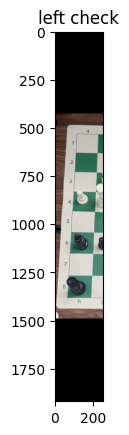

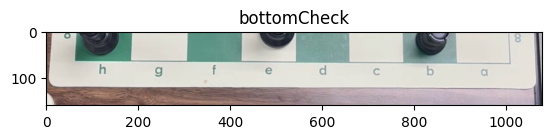

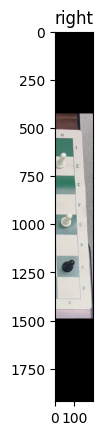

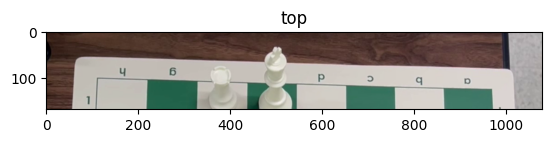

check left result border
detecting  2
detecting  3
detecting  5
detecting  6
detecting  7
detecting  8
detecting  h
s3: label is sufficient for inc order
passing  0


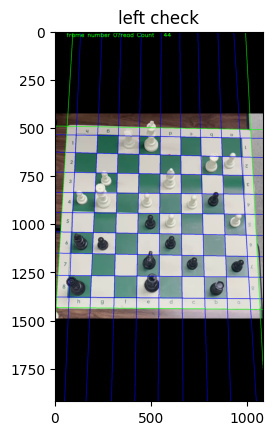

passing  250
passing  500
passing  750
passing  1000
passing  1250
passing  1500
passing  1750
passing  2000
passing  2250
passing  2500
passing  2750
passing  3000
passing  3250
passing  3500
passing  3750
passing  4000
passing  4250
passing  4500
passing  4750
passing  5000
passing  5250
passing  5500
passing  5750
passing  6000
passing  6250
passing  6500
passing  6750
passing  7000
passing  7250
passing  7500
passing  7750
passing  8000
passing  8250
passing  8500
passing  8750
passing  9000
passing  9250
passing  9500
passing  9750
passing  10000
passing  10250
passing  10500
passing  10750
passing  11000
passing  11250
passing  11500
passing  11750
passing  12000
passing  12250
passing  12500
passing  12750
passing  13000
passing  13250
passing  13500
passing  13750
passing  14000
passing  14250
passing  14500
passing  14750
passing  15000
passing  15250
passing  15500
passing  15750
passing  16000
passing  16250
passing  16500
passing  16750
passing  17000
passing  17250
passing

In [ ]:
nameWoT_list = collectNameWoType(src_vdo_folder)
#nameWoT_list = ["8_Move_student"]

for fileNameWoType in nameWoT_list:
  analyzeVideo(fileNameWoType)